In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["font.size"] = 10
plt.rcParams["figure.dpi"] = 120

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.1.0
NumPy version: 2.5.4


In [2]:
current_path = Path.cwd()

PROJECT_ROOT = None

for path in [current_path, *current_path.parents]:
    if (path / "data" / "raw" / "events.csv").exists():
        PROJECT_ROOT = path
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Не удалось найти data/raw/events.csv. "
        "Проверь расположение проекта."
    )

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "events.csv"

REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
TABLES_DIR = REPORTS_DIR / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data path:", DATA_PATH)
print("Figures directory:", FIGURES_DIR)
print("Tables directory:", TABLES_DIR)

Project root: /Users/hkkkkjv/Study/memory/4 course/boot/ecommerce-product-analytics
Data path: /Users/hkkkkjv/Study/memory/4 course/boot/ecommerce-product-analytics/data/raw/events.csv
Figures directory: /Users/hkkkkjv/Study/memory/4 course/boot/ecommerce-product-analytics/reports/figures
Tables directory: /Users/hkkkkjv/Study/memory/4 course/boot/ecommerce-product-analytics/reports/tables


In [3]:
events = pd.read_csv(DATA_PATH)

events["timestamp"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    utc=True,
    errors="coerce"
)

events = events.dropna(
    subset=["timestamp", "visitorid", "itemid", "event"]
).copy()

events["visitorid"] = events["visitorid"].astype("int64")
events["itemid"] = events["itemid"].astype("int64")

events = events.sort_values(
    ["visitorid", "timestamp"]
).reset_index(drop=True)

print("Dataset shape:", events.shape)
print("Date range:")
print(events["timestamp"].min())
print(events["timestamp"].max())

display(events.head())

Dataset shape: (2756101, 5)
Date range:
2015-05-03 03:00:04.384000+00:00
2015-09-18 02:59:47.788000+00:00


,timestamp,visitorid,event,itemid,transactionid
0,2015-09-11 20:49:49.439+00:00,0,view,285930,NaN
1,2015-09-11 20:52:39.591+00:00,0,view,357564,NaN
2,2015-09-11 20:55:17.175+00:00,0,view,67045,NaN
3,2015-08-13 17:46:06.444+00:00,1,view,72028,NaN
4,2015-08-07 17:51:44.567+00:00,2,view,325215,NaN


In [4]:
total_events = len(events)

unique_users = events["visitorid"].nunique()
unique_items = events["itemid"].nunique()

event_counts = (
    events["event"]
    .value_counts()
    .reindex(["view", "addtocart", "transaction"], fill_value=0)
)

unique_users_by_event = (
    events.groupby("event")["visitorid"]
    .nunique()
    .reindex(["view", "addtocart", "transaction"], fill_value=0)
)

total_views = int(event_counts["view"])
total_addtocarts = int(event_counts["addtocart"])
total_transaction_events = int(event_counts["transaction"])

total_orders = events.loc[
    events["event"] == "transaction",
    "transactionid"
].nunique()

unique_buyers = events.loc[
    events["event"] == "transaction",
    "visitorid"
].nunique()

overview = pd.DataFrame({
    "Metric": [
        "Total events",
        "Unique users",
        "Unique items",
        "Views",
        "Add to cart events",
        "Transaction events",
        "Unique orders",
        "Unique buyers"
    ],
    "Value": [
        total_events,
        unique_users,
        unique_items,
        total_views,
        total_addtocarts,
        total_transaction_events,
        total_orders,
        unique_buyers
    ]
})

display(overview)

,Metric,Value
0,Total events,2756101
1,Unique users,1407580
2,Unique items,235061
3,Views,2664312
4,Add to cart events,69332
5,Transaction events,22457
6,Unique orders,17672
7,Unique buyers,11719


In [5]:
event_distribution = pd.DataFrame({
    "event": event_counts.index,
    "event_count": event_counts.values
})

event_distribution["percentage"] = (
    event_distribution["event_count"]
    / event_distribution["event_count"].sum()
    * 100
)

display(event_distribution)

,event,event_count,percentage
0,view,2664312,96.669607
1,addtocart,69332,2.515583
2,transaction,22457,0.814810


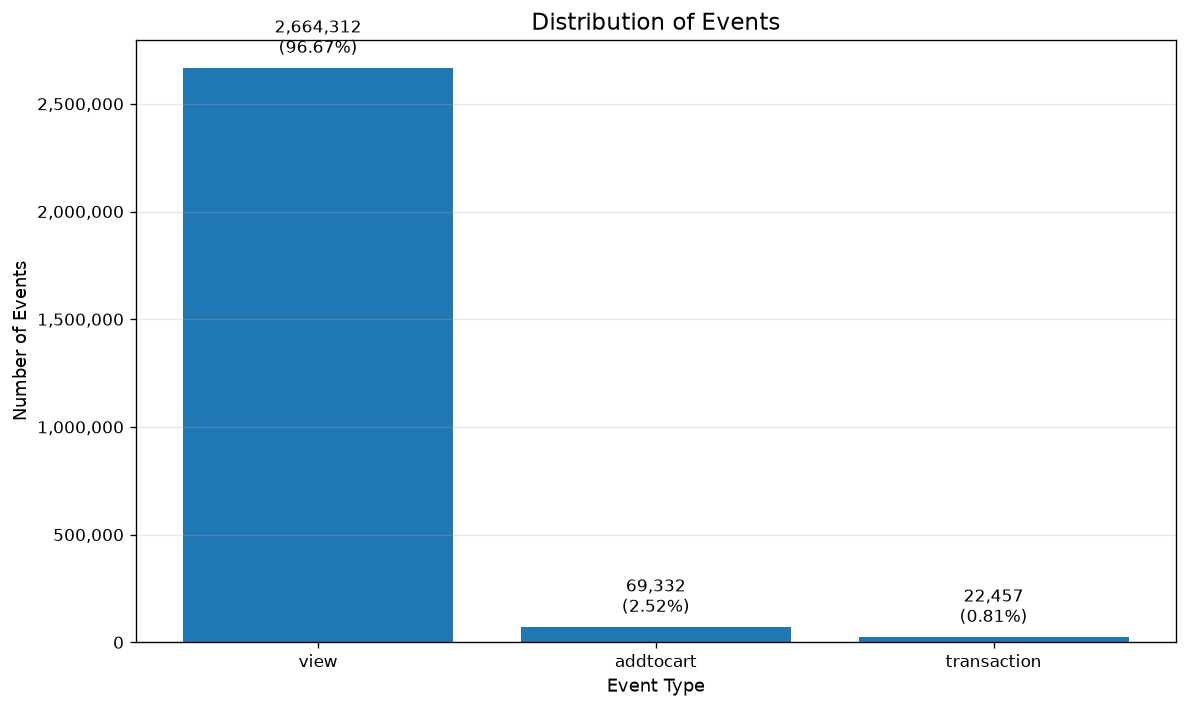

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    event_distribution["event"],
    event_distribution["event_count"]
)

ax.set_title("Distribution of Events")
ax.set_xlabel("Event Type")
ax.set_ylabel("Number of Events")

ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

for bar, percentage in zip(
    bars,
    event_distribution["percentage"]
):
    height = bar.get_height()

    ax.annotate(
        f"{height:,.0f}\n({percentage:.2f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "12_event_distribution.png",
    bbox_inches="tight"
)

plt.show()

In [7]:
user_activity = (
    events.groupby("visitorid")
    .agg(
        total_events=("event", "size"),
        views=("event", lambda x: (x == "view").sum()),
        addtocarts=("event", lambda x: (x == "addtocart").sum()),
        transactions=("event", lambda x: (x == "transaction").sum())
    )
    .reset_index()
)

user_activity["user_segment"] = np.select(
    [
        user_activity["transactions"] > 0,
        user_activity["addtocarts"] > 0,
        user_activity["views"] > 0
    ],
    [
        "Buyer",
        "Cart user",
        "Viewer"
    ],
    default="Other"
)

user_segments = (
    user_activity["user_segment"]
    .value_counts()
    .reindex(["Viewer", "Cart user", "Buyer"], fill_value=0)
    .rename_axis("user_segment")
    .reset_index(name="users")
)

user_segments["percentage"] = (
    user_segments["users"]
    / user_segments["users"].sum()
    * 100
)

display(user_segments)

,user_segment,users,percentage
0,Viewer,1368715,97.238878
1,Cart user,27146,1.928558
2,Buyer,11719,0.832564


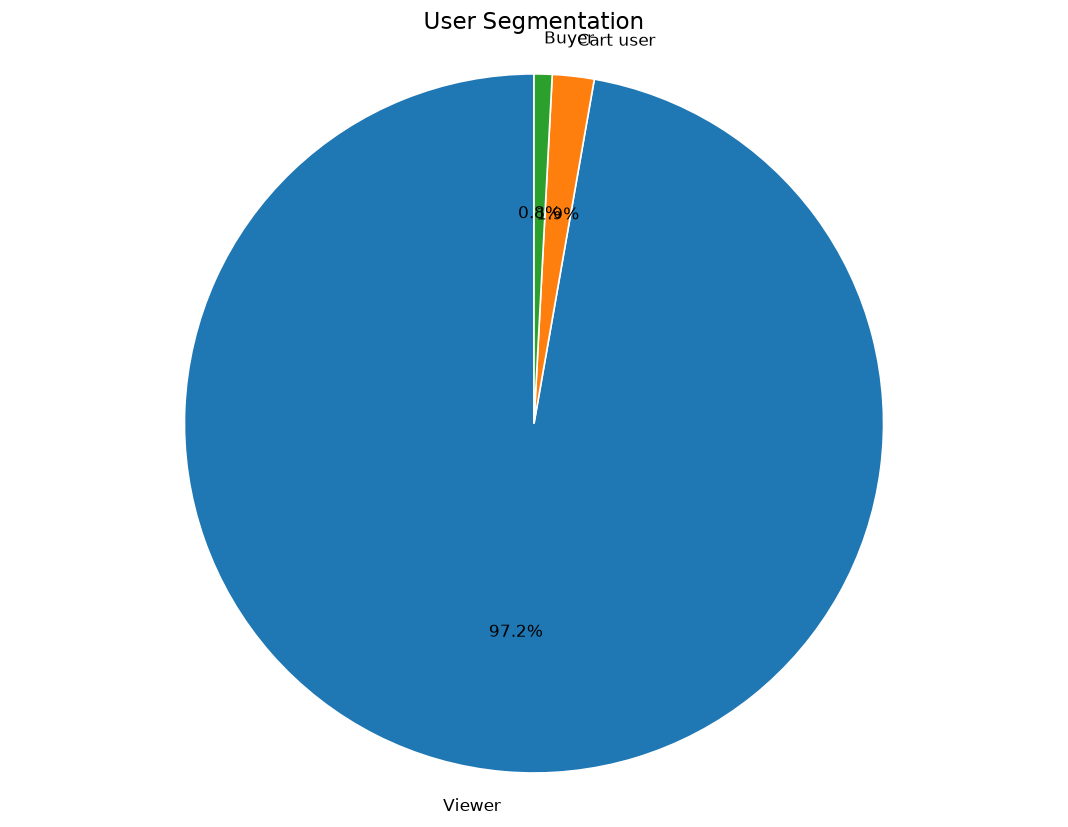

In [8]:
fig, ax = plt.subplots(figsize=(9, 7))

ax.pie(
    user_segments["users"],
    labels=user_segments["user_segment"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"}
)

ax.set_title("User Segmentation")
ax.axis("equal")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "12_user_segments.png",
    bbox_inches="tight"
)

plt.show()

In [9]:
daily_activity = (
    events.assign(date=events["timestamp"].dt.floor("D"))
    .groupby("date")
    .agg(
        total_events=("event", "size"),
        unique_users=("visitorid", "nunique"),
        views=("event", lambda x: (x == "view").sum()),
        addtocarts=("event", lambda x: (x == "addtocart").sum()),
        transactions=("event", lambda x: (x == "transaction").sum())
    )
    .reset_index()
)

display(daily_activity.head())

,date,total_events,unique_users,views,addtocarts,transactions
0,2015-05-03 00:00:00+00:00,13683,7865,13304,296,83
1,2015-05-04 00:00:00+00:00,19414,11019,18681,579,154
2,2015-05-05 00:00:00+00:00,23015,13084,22225,565,225
3,2015-05-06 00:00:00+00:00,23920,13687,23015,647,258
4,2015-05-07 00:00:00+00:00,23164,13086,22369,578,217


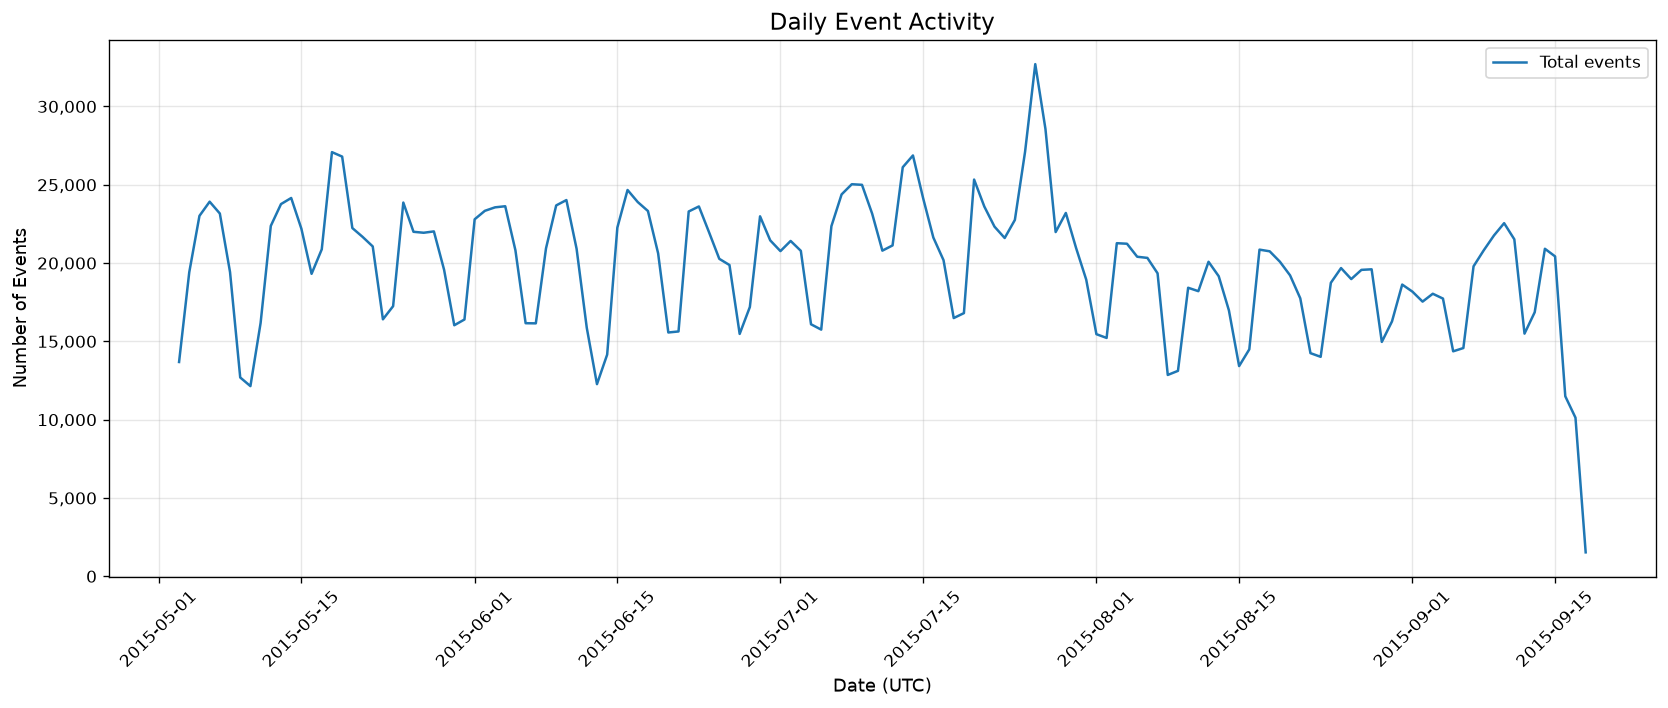

In [10]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    daily_activity["date"],
    daily_activity["total_events"],
    label="Total events",
    linewidth=1.5
)

ax.set_title("Daily Event Activity")
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Number of Events")

ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

ax.grid(alpha=0.3)
ax.legend()

plt.xticks(rotation=45)
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "12_daily_activity.png",
    bbox_inches="tight"
)

plt.show()

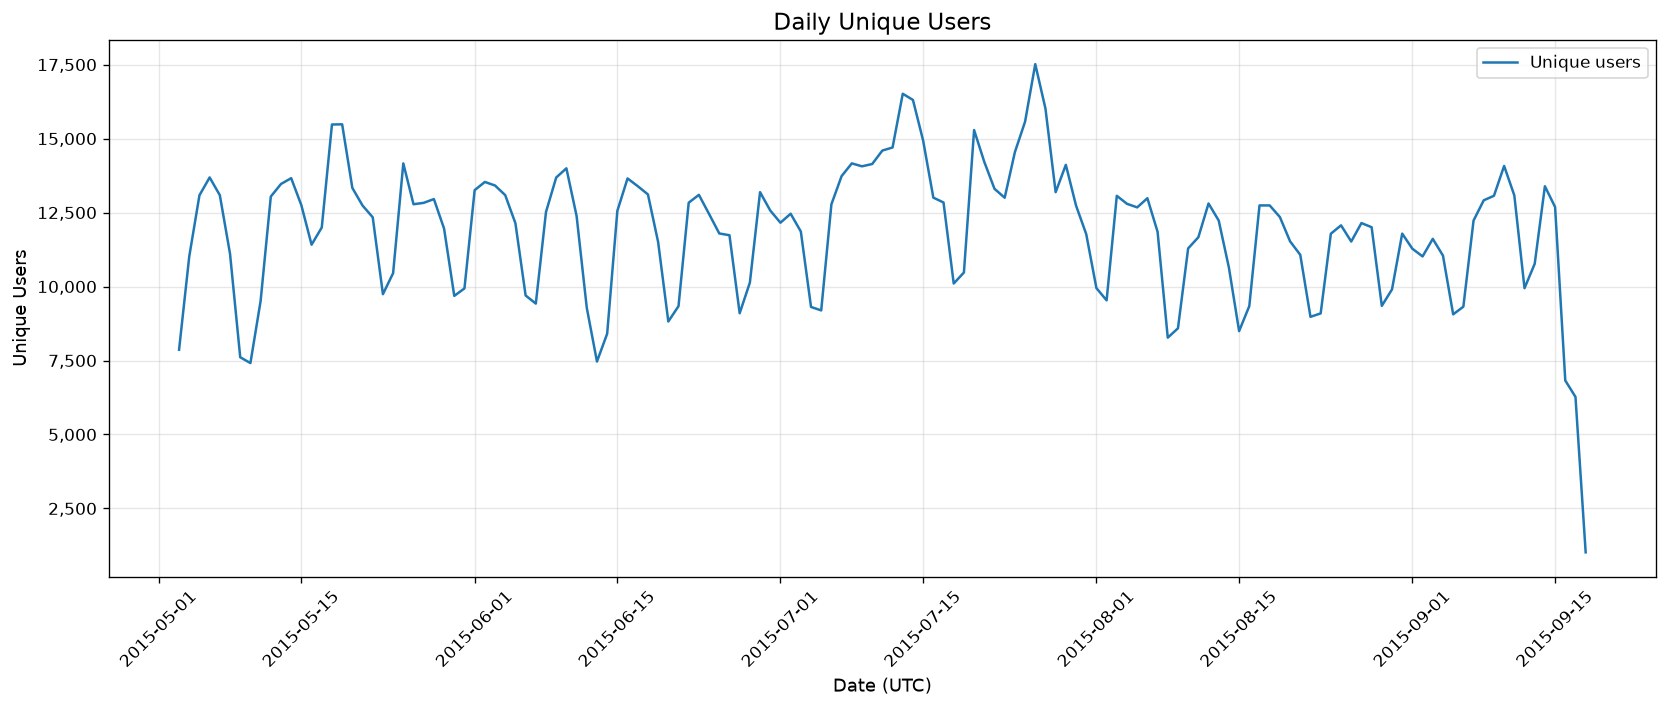

In [11]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    daily_activity["date"],
    daily_activity["unique_users"],
    label="Unique users",
    linewidth=1.5
)

ax.set_title("Daily Unique Users")
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Unique Users")

ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

ax.grid(alpha=0.3)
ax.legend()

plt.xticks(rotation=45)
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "12_daily_unique_users.png",
    bbox_inches="tight"
)

plt.show()

In [12]:
hourly_activity = (
    events.assign(hour=events["timestamp"].dt.hour)
    .groupby("hour")
    .agg(
        total_events=("event", "size"),
        unique_users=("visitorid", "nunique")
    )
    .reindex(range(24), fill_value=0)
    .reset_index()
)

display(hourly_activity)

,hour,total_events,unique_users
0,0,144303,89567
1,1,140702,88915
2,2,145879,92636
3,3,150860,96539
4,4,147184,93458
5,5,119572,75804
6,6,76972,49570
7,7,43944,28440
8,8,25309,16918
9,9,17909,12318


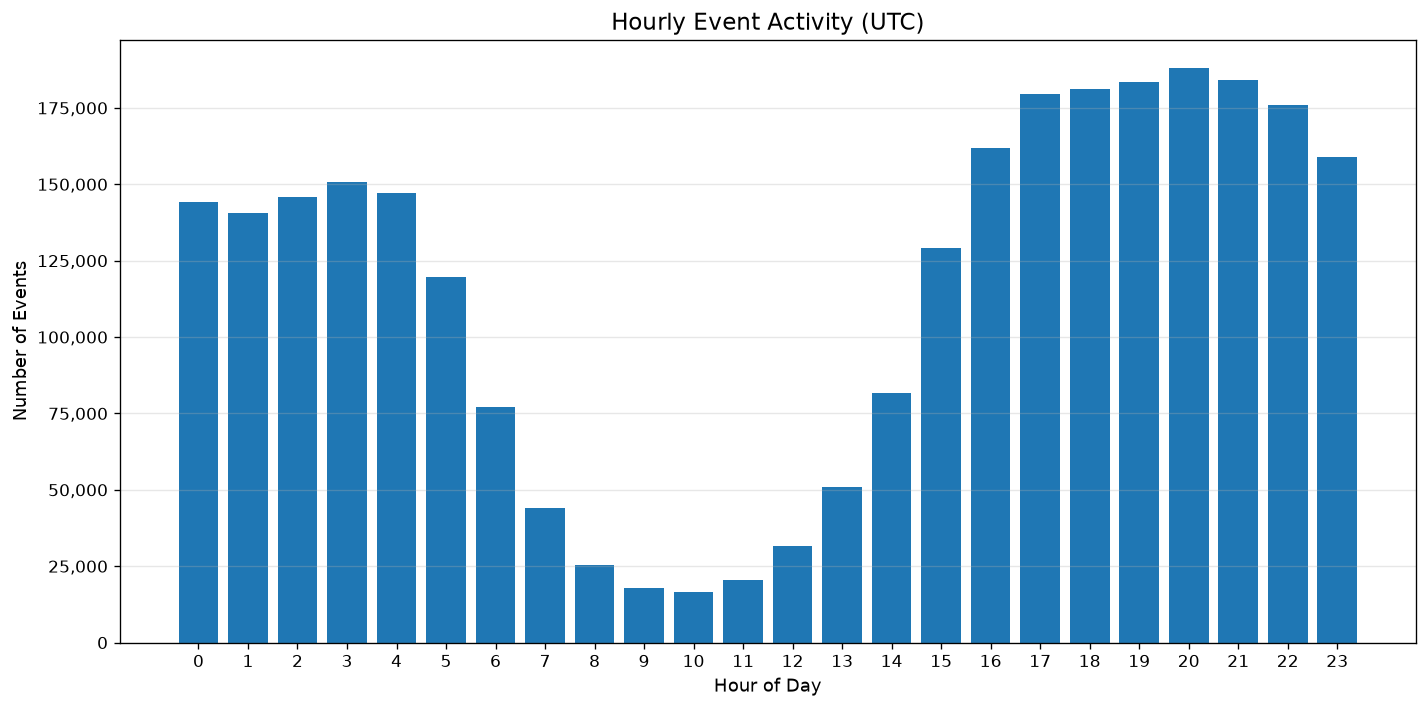

In [13]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    hourly_activity["hour"],
    hourly_activity["total_events"]
)

ax.set_title("Hourly Event Activity (UTC)")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Number of Events")

ax.set_xticks(range(24))
ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "12_hourly_activity.png",
    bbox_inches="tight"
)

plt.show()

In [14]:
user_event_times = (
    events.pivot_table(
        index="visitorid",
        columns="event",
        values="timestamp",
        aggfunc="min"
    )
    .reindex(
        columns=["view", "addtocart", "transaction"]
    )
)

user_event_times.columns = [
    "first_view",
    "first_addtocart",
    "first_transaction"
]

view_users = user_event_times["first_view"].notna()

view_to_cart = (
    view_users
    & user_event_times["first_addtocart"].notna()
    & (
        user_event_times["first_view"]
        <= user_event_times["first_addtocart"]
    )
)

full_funnel = (
    view_to_cart
    & user_event_times["first_transaction"].notna()
    & (
        user_event_times["first_addtocart"]
        <= user_event_times["first_transaction"]
    )
)

funnel = pd.DataFrame({
    "stage": ["View", "Add to cart", "Transaction"],
    "users": [
        int(view_users.sum()),
        int(view_to_cart.sum()),
        int(full_funnel.sum())
    ]
})

funnel["conversion_from_view"] = (
    funnel["users"] / funnel.loc[0, "users"]
)

funnel["conversion_from_previous"] = (
    funnel["users"] / funnel["users"].shift(1)
)

funnel.loc[0, "conversion_from_previous"] = 1.0

display(funnel)

,stage,users,conversion_from_view,conversion_from_previous
0,View,1404179,1.000000,1.000000
1,Add to cart,32272,0.022983,0.022983
2,Transaction,9682,0.006895,0.300012


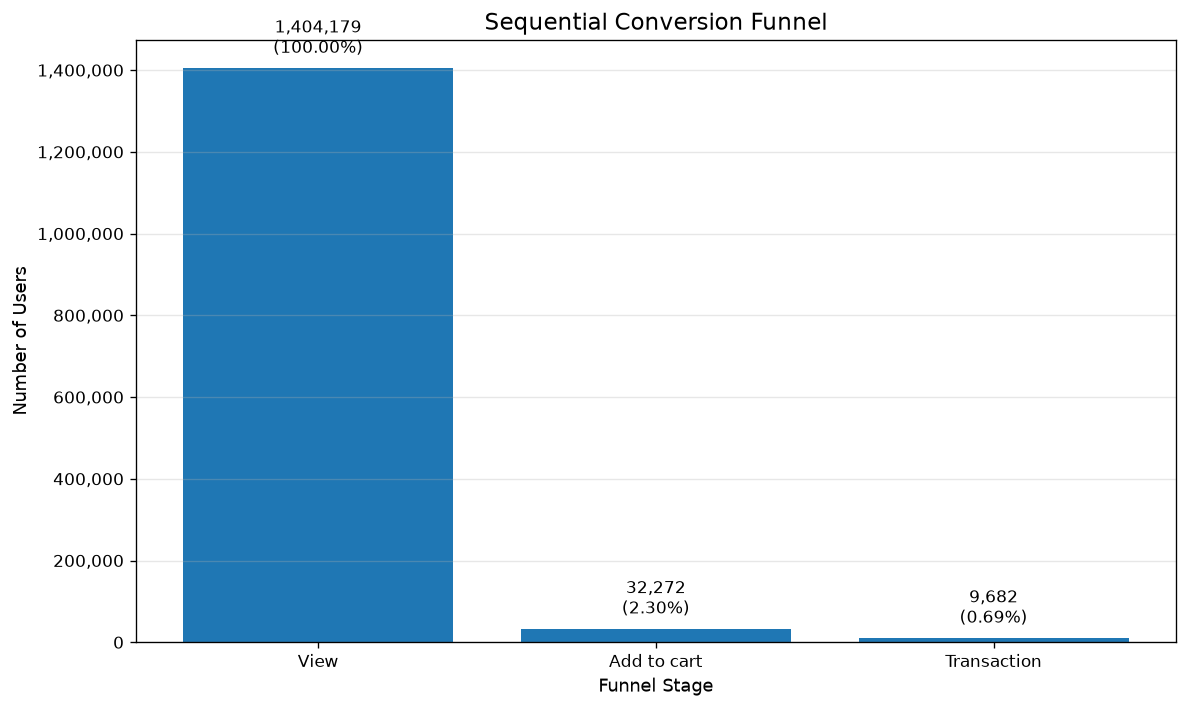

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    funnel["stage"],
    funnel["users"]
)

ax.set_title("Sequential Conversion Funnel")
ax.set_xlabel("Funnel Stage")
ax.set_ylabel("Number of Users")

ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

for i, bar in enumerate(bars):
    height = bar.get_height()

    conversion = funnel.loc[i, "conversion_from_view"]

    ax.annotate(
        f"{height:,.0f}\n({conversion:.2%})",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "12_conversion_funnel.png",
    bbox_inches="tight"
)

plt.show()

In [27]:
item_performance = (
    events.groupby("itemid")
    .agg(
        views=("event", lambda x: (x == "view").sum()),
        addtocarts=("event", lambda x: (x == "addtocart").sum()),
        transaction_events=(
            "event",
            lambda x: (x == "transaction").sum()
        ),
        unique_viewers=(
            "visitorid",
            lambda x: x[
                events.loc[x.index, "event"] == "view"
            ].nunique()
        ),
        unique_orders=(
            "transactionid",
            "nunique"
        )
    )
    .reset_index()
)

top_viewed_items = (
    item_performance
    .sort_values("views", ascending=False)
    .head(20)
    .copy()
)

top_purchased_items = (
    item_performance
    .sort_values("transaction_events", ascending=False)
    .head(20)
    .copy()
)

display(top_viewed_items)
display(top_purchased_items)

,itemid,views,addtocarts,transaction_events,unique_viewers,unique_orders
94720,187946,3410,2,0,2911,0
232496,461686,2539,306,133,1379,133
2719,5411,2325,9,0,2078,0
186716,370653,1854,0,0,1577,0
110536,219512,1740,48,12,1358,12
150148,298009,1642,0,0,1342,0
49024,96924,1633,0,0,1359,0
156023,309778,1565,48,15,1053,15
129504,257040,1531,89,27,979,27
193605,384302,1528,65,15,1143,15


,itemid,views,addtocarts,transaction_events,unique_viewers,unique_orders
232496,461686,2539,306,133,1379,133
60527,119736,752,44,97,251,96
107690,213834,293,17,92,199,92
157492,312728,947,162,46,602,46
3980,7943,1346,97,46,843,46
224330,445351,939,89,45,618,45
24339,48030,986,95,41,628,41
125146,248455,575,52,38,291,38
212061,420960,796,60,38,371,38
8763,17478,631,72,37,378,37


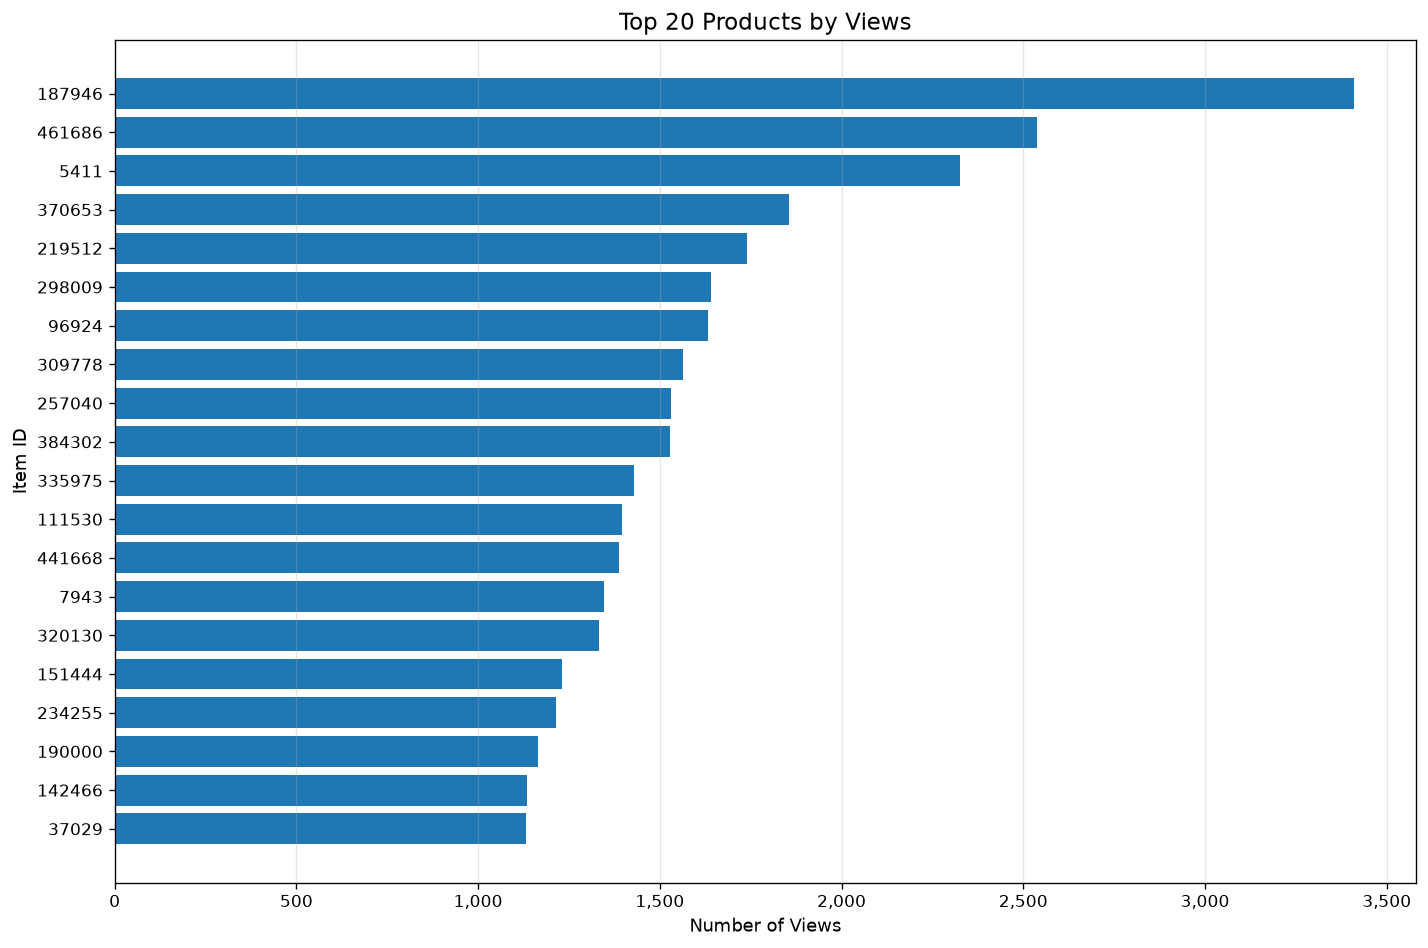

In [28]:
fig, ax = plt.subplots(figsize=(12, 8))

plot_data = top_viewed_items.sort_values("views")

ax.barh(
    plot_data["itemid"].astype(str),
    plot_data["views"]
)

ax.set_title("Top 20 Products by Views")
ax.set_xlabel("Number of Views")
ax.set_ylabel("Item ID")

ax.xaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "12_top_viewed_items.png",
    bbox_inches="tight"
)

plt.show()

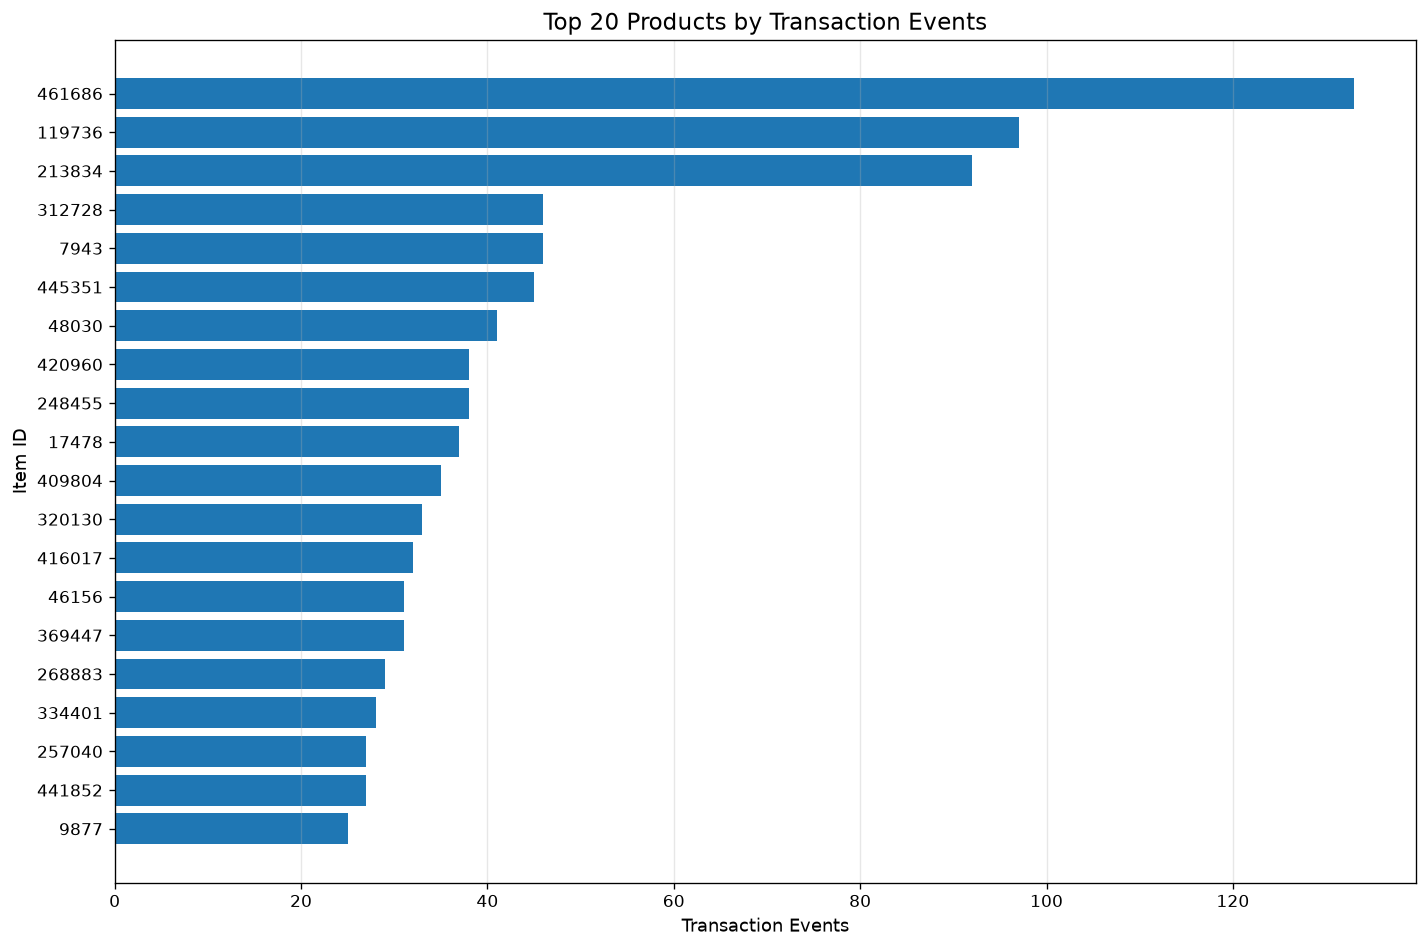

In [29]:
fig, ax = plt.subplots(figsize=(12, 8))

plot_data = top_purchased_items.sort_values(
    "transaction_events"
)

ax.barh(
    plot_data["itemid"].astype(str),
    plot_data["transaction_events"]
)

ax.set_title("Top 20 Products by Transaction Events")
ax.set_xlabel("Transaction Events")
ax.set_ylabel("Item ID")

ax.xaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "12_top_purchased_items.png",
    bbox_inches="tight"
)

plt.show()

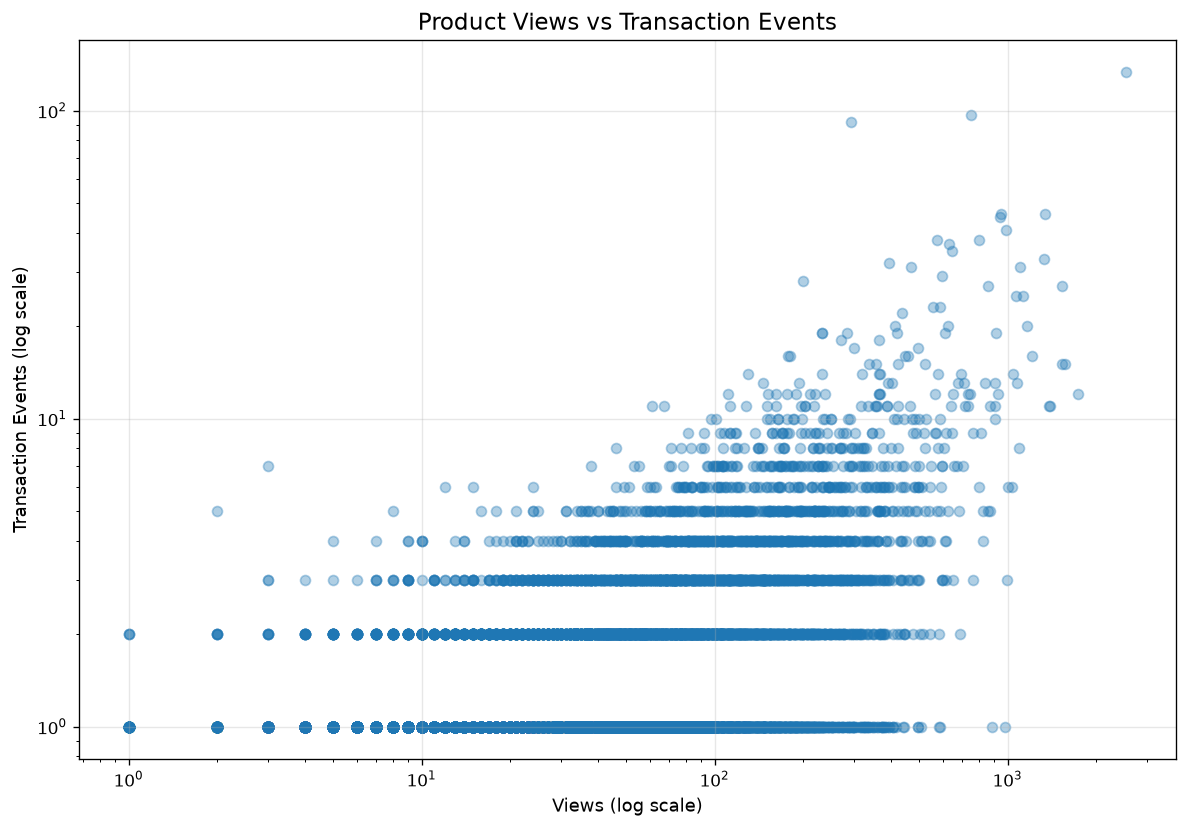

In [30]:
fig, ax = plt.subplots(figsize=(10, 7))

plot_data = item_performance[
    (item_performance["views"] > 0)
    & (item_performance["transaction_events"] > 0)
]

ax.scatter(
    plot_data["views"],
    plot_data["transaction_events"],
    alpha=0.35
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_title("Product Views vs Transaction Events")
ax.set_xlabel("Views (log scale)")
ax.set_ylabel("Transaction Events (log scale)")

ax.grid(alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "12_views_vs_transactions.png",
    bbox_inches="tight"
)

plt.show()

In [31]:
transactions = events[
    (events["event"] == "transaction")
    & events["transactionid"].notna()
].copy()

orders = (
    transactions
    .groupby(["transactionid", "visitorid"])
    .agg(
        items_in_order=("itemid", "nunique")
    )
    .reset_index()
)

order_size_distribution = (
    orders["items_in_order"]
    .value_counts()
    .sort_index()
    .rename_axis("items_in_order")
    .reset_index(name="orders")
)

display(order_size_distribution)

order_summary = pd.DataFrame({
    "Metric": [
        "Unique transaction IDs",
        "Unique buyers",
        "Average items per order group",
        "Maximum items in an order group",
        "Multi-item order groups"
    ],
    "Value": [
        transactions["transactionid"].nunique(),
        transactions["visitorid"].nunique(),
        orders["items_in_order"].mean(),
        orders["items_in_order"].max(),
        (orders["items_in_order"] > 1).sum()
    ]
})

display(order_summary)

,items_in_order,orders
0,1,15029
1,2,1740
2,3,505
3,4,187
4,5,79
5,6,42
6,7,30
7,8,15
8,9,12
9,10,9


,Metric,Value
0,Unique transaction IDs,17672.000000
1,Unique buyers,11719.000000
2,Average items per order group,1.263185
3,Maximum items in an order group,31.000000
4,Multi-item order groups,2643.000000


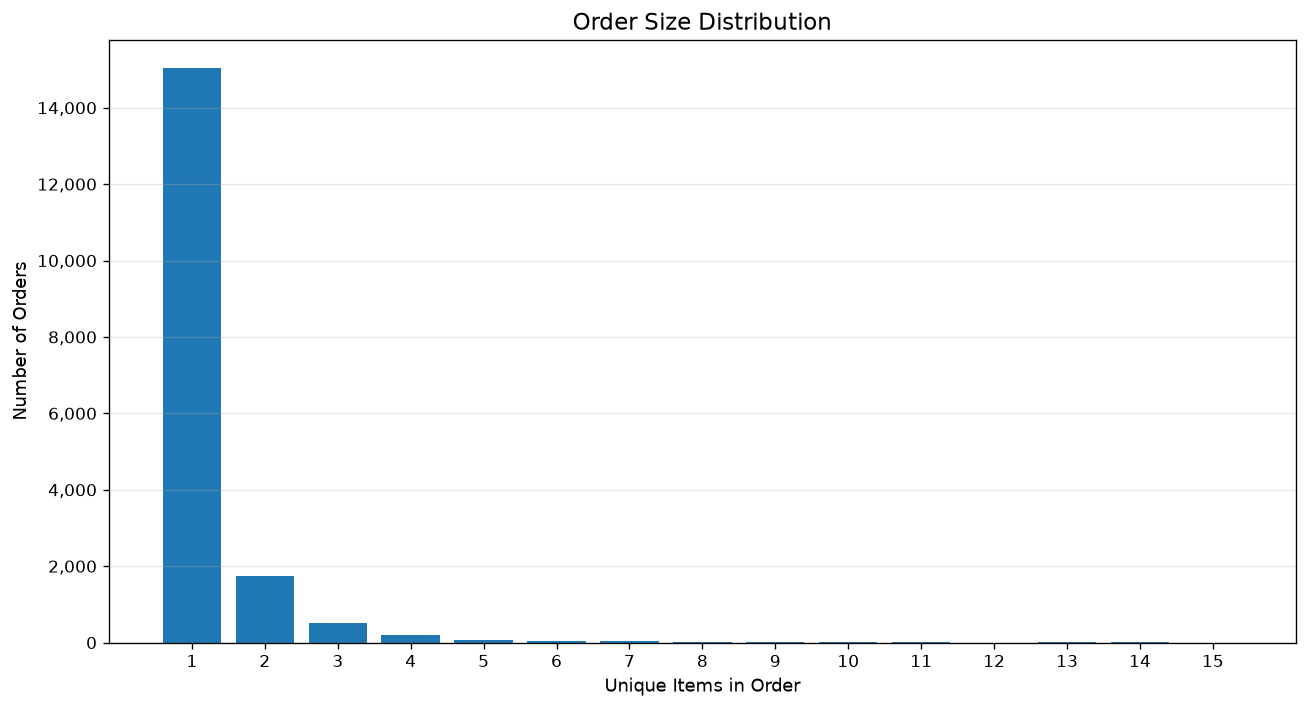

In [32]:
fig, ax = plt.subplots(figsize=(11, 6))

plot_data = order_size_distribution.head(15)

ax.bar(
    plot_data["items_in_order"].astype(str),
    plot_data["orders"]
)

ax.set_title("Order Size Distribution")
ax.set_xlabel("Unique Items in Order")
ax.set_ylabel("Number of Orders")

ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "12_order_size_distribution.png",
    bbox_inches="tight"
)

plt.show()

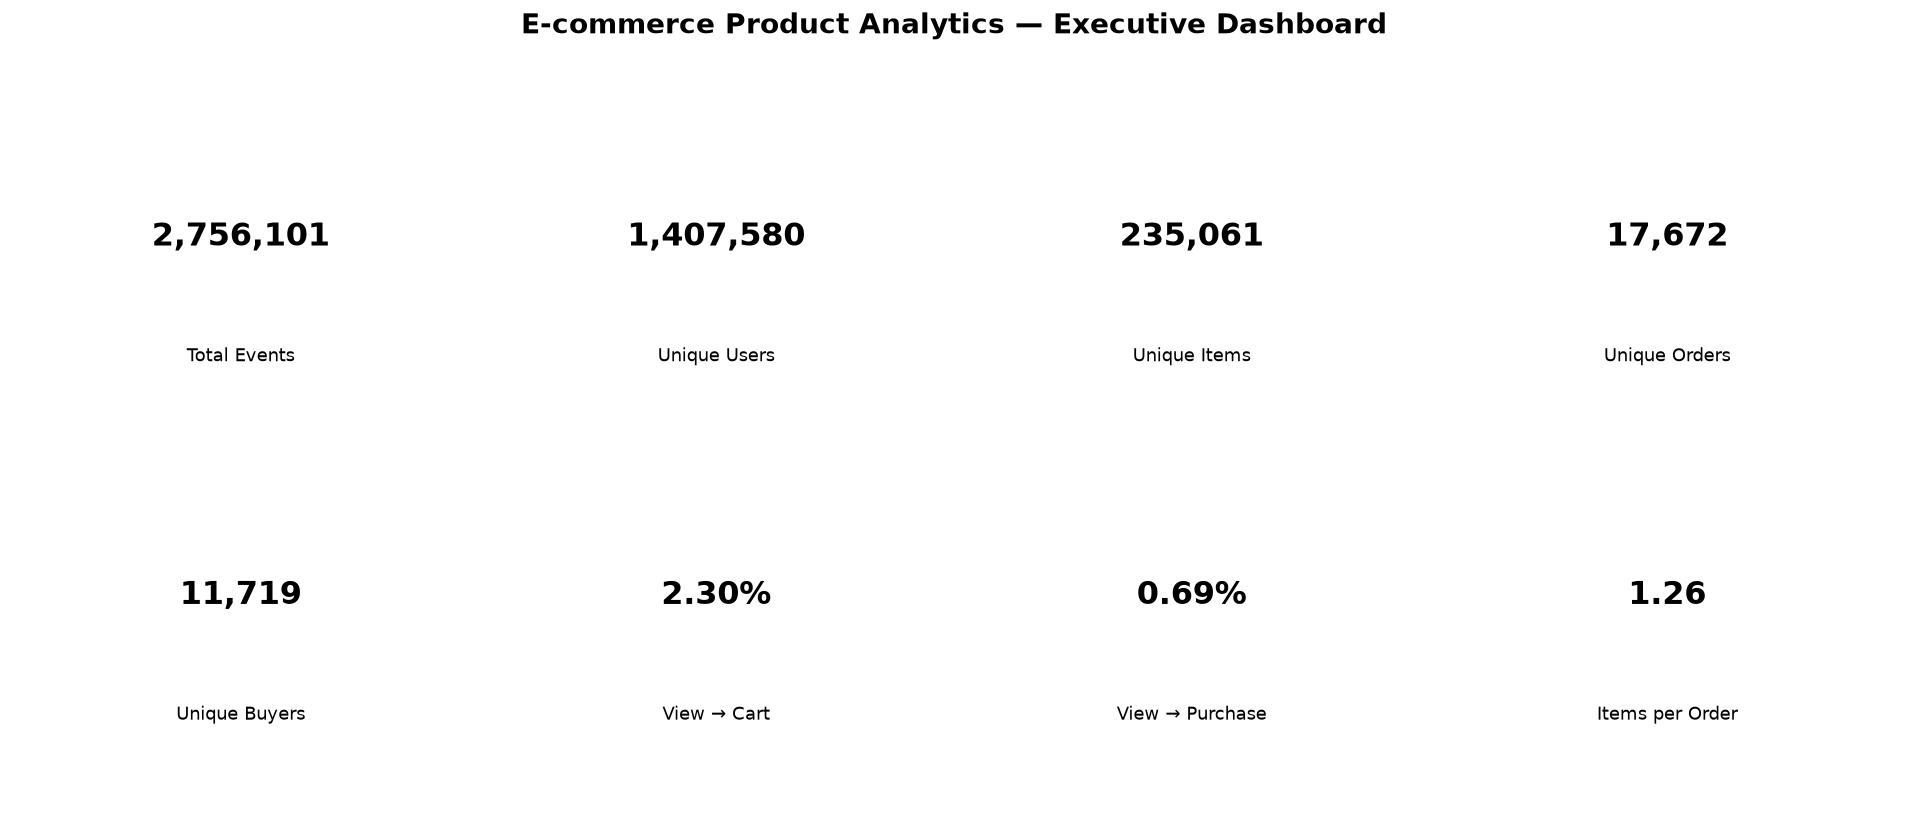

In [33]:
conversion_view_cart = (
    funnel.loc[1, "conversion_from_view"]
)

conversion_view_transaction = (
    funnel.loc[2, "conversion_from_view"]
)

conversion_cart_transaction = (
    funnel.loc[2, "conversion_from_previous"]
)

average_items_per_order = orders["items_in_order"].mean()

kpi_values = [
    ("Total Events", f"{total_events:,.0f}"),
    ("Unique Users", f"{unique_users:,.0f}"),
    ("Unique Items", f"{unique_items:,.0f}"),
    ("Unique Orders", f"{total_orders:,.0f}"),
    ("Unique Buyers", f"{unique_buyers:,.0f}"),
    ("View → Cart", f"{conversion_view_cart:.2%}"),
    ("View → Purchase", f"{conversion_view_transaction:.2%}"),
    ("Items per Order", f"{average_items_per_order:.2f}")
]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for ax, (title, value) in zip(axes.flat, kpi_values):
    ax.axis("off")

    ax.text(
        0.5,
        0.65,
        value,
        ha="center",
        va="center",
        fontsize=19,
        fontweight="bold"
    )

    ax.text(
        0.5,
        0.30,
        title,
        ha="center",
        va="center",
        fontsize=11
    )

fig.suptitle(
    "E-commerce Product Analytics — Executive Dashboard",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.93])

fig.savefig(
    FIGURES_DIR / "12_executive_dashboard.png",
    bbox_inches="tight"
)

plt.show()

In [34]:
dashboard_kpis = pd.DataFrame({
    "metric": [
        "total_events",
        "unique_users",
        "unique_items",
        "views",
        "addtocart_events",
        "transaction_events",
        "unique_orders",
        "unique_buyers",
        "view_to_cart_conversion",
        "view_to_transaction_conversion",
        "cart_to_transaction_conversion",
        "average_items_per_order"
    ],
    "value": [
        total_events,
        unique_users,
        unique_items,
        total_views,
        total_addtocarts,
        total_transaction_events,
        total_orders,
        unique_buyers,
        conversion_view_cart,
        conversion_view_transaction,
        conversion_cart_transaction,
        average_items_per_order
    ]
})

tables_to_export = {
    "12_overview.csv": overview,
    "12_event_distribution.csv": event_distribution,
    "12_user_segments.csv": user_segments,
    "12_daily_activity.csv": daily_activity,
    "12_hourly_activity.csv": hourly_activity,
    "12_conversion_funnel.csv": funnel,
    "12_top_viewed_items.csv": top_viewed_items,
    "12_top_purchased_items.csv": top_purchased_items,
    "12_item_performance.csv": item_performance,
    "12_order_size_distribution.csv": order_size_distribution,
    "12_order_summary.csv": order_summary,
    "12_dashboard_kpis.csv": dashboard_kpis
}

for filename, dataframe in tables_to_export.items():
    dataframe.to_csv(
        TABLES_DIR / filename,
        index=False
    )

print(f"Exported {len(tables_to_export)} tables:")

for filename in tables_to_export:
    print(filename)

Exported 12 tables:
12_overview.csv
12_event_distribution.csv
12_user_segments.csv
12_daily_activity.csv
12_hourly_activity.csv
12_conversion_funnel.csv
12_top_viewed_items.csv
12_top_purchased_items.csv
12_item_performance.csv
12_order_size_distribution.csv
12_order_summary.csv
12_dashboard_kpis.csv


In [35]:
figure_files = sorted(
    FIGURES_DIR.glob("12_*.png")
)

table_files = sorted(
    TABLES_DIR.glob("12_*.csv")
)

print("Figures saved:", len(figure_files))

for file in figure_files:
    print(file.name)

print("\nTables saved:", len(table_files))

for file in table_files:
    print(file.name)

assert len(figure_files) == 11, (
    f"Ожидалось 11 графиков, найдено {len(figure_files)}"
)

assert len(table_files) == len(tables_to_export), (
    "Количество экспортированных таблиц не совпадает"
)

print("\nAll export checks passed.")

Figures saved: 11
12_conversion_funnel.png
12_daily_activity.png
12_daily_unique_users.png
12_event_distribution.png
12_executive_dashboard.png
12_hourly_activity.png
12_order_size_distribution.png
12_top_purchased_items.png
12_top_viewed_items.png
12_user_segments.png
12_views_vs_transactions.png

Tables saved: 12
12_conversion_funnel.csv
12_daily_activity.csv
12_dashboard_kpis.csv
12_event_distribution.csv
12_hourly_activity.csv
12_item_performance.csv
12_order_size_distribution.csv
12_order_summary.csv
12_overview.csv
12_top_purchased_items.csv
12_top_viewed_items.csv
12_user_segments.csv

All export checks passed.


In [36]:
print("=" * 60)
print("NOTEBOOK 12 — FINAL SUMMARY")
print("=" * 60)

print(f"Total events: {total_events:,}")
print(f"Unique users: {unique_users:,}")
print(f"Unique items: {unique_items:,}")

print("\nEvent distribution:")
display(event_distribution)

print("\nUser segments:")
display(user_segments)

print("\nConversion funnel:")
display(funnel)

print("\nOrder summary:")
display(order_summary)

print("\nDashboard KPIs:")
display(dashboard_kpis)

print("\nFigures exported:", len(figure_files))
print("Tables exported:", len(table_files))

print("\nAll export checks passed.")
print("=" * 60)

NOTEBOOK 12 — FINAL SUMMARY
Total events: 2,756,101
Unique users: 1,407,580
Unique items: 235,061

Event distribution:


,event,event_count,percentage
0,view,2664312,96.669607
1,addtocart,69332,2.515583
2,transaction,22457,0.814810



User segments:


,user_segment,users,percentage
0,Viewer,1368715,97.238878
1,Cart user,27146,1.928558
2,Buyer,11719,0.832564



Conversion funnel:


,stage,users,conversion_from_view,conversion_from_previous
0,View,1404179,1.000000,1.000000
1,Add to cart,32272,0.022983,0.022983
2,Transaction,9682,0.006895,0.300012



Order summary:


,Metric,Value
0,Unique transaction IDs,17672.000000
1,Unique buyers,11719.000000
2,Average items per order group,1.263185
3,Maximum items in an order group,31.000000
4,Multi-item order groups,2643.000000



Dashboard KPIs:


,metric,value
0,total_events,2.756101e+06
1,unique_users,1.407580e+06
2,unique_items,2.350610e+05
3,views,2.664312e+06
4,addtocart_events,6.933200e+04
5,transaction_events,2.245700e+04
6,unique_orders,1.767200e+04
7,unique_buyers,1.171900e+04
8,view_to_cart_conversion,2.298282e-02
9,view_to_transaction_conversion,6.895132e-03



Figures exported: 11
Tables exported: 12

All export checks passed.
